# Laboratorio: selección de variables con Random Forest
### Dataset Diabetes de scikit-learn
**Universidad Cooperativa de Colombia · Analítica de Datos**  
**Docente:** Luis Miguel Gómez Meneses  


**Objetivo:** comparar un modelo que usa diez variables con modelos que usan solo tres.

Trabajaremos con el dataset real **Diabetes**, incluido en scikit-learn, y tres familias de selección:
1. **Filtrado:** correlación con la variable objetivo.
2. **Wrapper:** selección hacia adelante y hacia atrás.
3. **Basada en el modelo:** importancias aprendidas por Random Forest, relacionadas con los métodos embebidos vistos en las diapositivas.

Ejecuta las celdas en orden y responde las preguntas en las celdas de Markdown. No necesitas descargar datos ni activar una GPU.

## 1. ¿Qué es Random Forest y cómo funciona?

**Random Forest (bosque aleatorio)** es un modelo que combina muchos árboles de decisión. Un árbol aprende reglas para dividir los datos.

En este laboratorio haremos **regresión**, porque queremos predecir un número.

El bosque funciona así:
1. Cada árbol se entrena con una muestra aleatoria de las filas de entrenamiento, **con reemplazo**: una fila puede aparecer varias veces.
2. En cada división del árbol se consideran algunas variables elegidas al azar. Así se favorece la diversidad entre árboles.
3. Cada árbol produce una predicción numérica.
4. El bosque **promedia las predicciones** de todos los árboles.


## 2. Importar las librerías
- **NumPy:** calcular la raíz cuadrada para el RMSE.
- **Pandas:** organizar tablas.
- **Matplotlib:** dibujar gráficos.
- **Scikit-learn:** cargar el dataset, separar datos, entrenar Random Forest y calcular el error.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.datasets import load_diabetes

## 3. Cargar el dataset Diabetes

Usaremos **Diabetes**, un conjunto de datos real incluido en scikit-learn: **442 registros y 10 variables de entrada**. Cada registro corresponde a un paciente. Se carga directamente, sin descargar archivos externos.

### Variables de entrada: X

Son las características registradas al inicio del estudio que utilizaremos para realizar la predicción:

| Entrada | Significado |
|---|---|
| `age` | Edad del paciente. |
| `sex` | Sexo representado mediante una codificación numérica. |
| `bmi` | Índice de masa corporal. |
| `bp` | Presión arterial media. |
| `s1` | Colesterol total en sangre. |
| `s2` | Lipoproteínas de baja densidad (LDL). |
| `s3` | Lipoproteínas de alta densidad (HDL). |
| `s4` | Cociente entre el colesterol total y el HDL. |
| `s5` | Posiblemente, el logaritmo del nivel de triglicéridos en sangre, según la documentación de scikit-learn. |
| `s6` | Nivel de glucosa en sangre. |

### ¿Por qué las entradas tienen valores pequeños o negativos?

Las entradas se entregan **centradas y escaladas por defecto**. Sus valores no representan directamente las unidades originales.

Por ejemplo, `age = 0.03` **no significa que el paciente tenga 0.03 años**. Es el valor de la edad después de esa transformación. De igual manera, un valor negativo en una variable sanguínea no significa que exista una concentración negativa.

Las 10 columnas son numéricas, aunque `sex` representa una categoría codificada.

### Variable de salida: y

La salida **y** es una **medida numérica de progresión de la diabetes un año después del registro inicial**.

El modelo utilizará las características iniciales del paciente para estimar esa medida posterior.

**Predeciremos un número, por eso es un problema de regresión.** No estamos clasificando a los pacientes entre “tiene diabetes” y “no tiene diabetes”.

### ¿Qué significa el valor numérico de y?

En este dataset, los valores observados de **y van de 25 a 346**.

Si un paciente tiene `y = 150`, significa que su puntuación registrada de progresión de la enfermedad es **150**. Sin embargo:

- No significa que tenga **150 % de diabetes**.
- No significa que su glucosa sea de **150 mg/dL**.
- No representa una probabilidad de tener diabetes.
- No podemos afirmar que `y = 200` equivalga al doble de gravedad que `y = 100`.

**La documentación de scikit-learn no detalla cómo se construyó esta puntuación ni su escala clínica exacta.** Por eso, la utilizaremos como una variable objetivo numérica sin asignarle una interpretación clínica adicional.

### ¿Qué aprenderá a hacer nuestro modelo?

Aprenderá una relación entre las entradas **X** y la salida **y** para generar una predicción.

Por ejemplo, si un paciente tiene un valor real de `y = 150` y el modelo predice `140`, la predicción queda **10 puntos por debajo del valor registrado**. El RMSE resumirá los errores de predicción del conjunto evaluado, expresados en puntos de esta misma escala.

### ¿Qué compararemos en el laboratorio?

No sabemos de antemano cuál será el mejor subconjunto de variables: lo exploraremos con los tres enfoques de selección.

Para comparar de forma sencilla, cada selección conservará **tres variables**. Evaluaremos si un modelo con esas tres entradas mantiene un desempeño similar al modelo que utiliza las diez.

**Nuestro objetivo es comprender la selección de variables y comparar el error de predicción.**

In [4]:
dataset = load_diabetes(as_frame=True)
X = dataset.data
y = dataset.target.rename("y")
datos = X.copy()
datos["y"] = y
display(datos.head().round(3))
print("Registros:", X.shape[0])
print("Variables de entrada:", X.shape[1])
print("Datos faltantes:", datos.isna().sum().sum())

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,y
0,0.038,0.051,0.062,0.022,-0.044,-0.035,-0.043,-0.003,0.020,-0.018,151.0
1,-0.002,-0.045,-0.051,-0.026,-0.008,-0.019,0.074,-0.039,-0.068,-0.092,75.0
2,0.085,0.051,0.044,-0.006,-0.046,-0.034,-0.032,-0.003,0.003,-0.026,141.0
3,-0.089,-0.045,-0.012,-0.037,0.012,0.025,-0.036,0.034,0.023,-0.009,206.0
4,0.005,-0.045,-0.036,0.022,0.004,0.016,0.008,-0.003,-0.032,-0.047,135.0


Registros: 442
Variables de entrada: 10
Datos faltantes: 0


**Pregunta 1.** ¿Cuántos registros y variables de entrada tiene el dataset? ¿Qué representa la salida y por qué usaremos regresión?

**Respuesta:**

## 4. Separar entrenamiento, validación y prueba

Usaremos tres grupos de filas:

| Grupo | Porcentaje aproximado | Uso |
|---|---:|---|
| Entrenamiento | 60 % | Entrenar modelos, calcular correlaciones e importancias |
| Validación | 20 % | Comparar los subconjuntos del método wrapper |
| Prueba | 20 % | Comparar los modelos al final |

**No utilizaremos la prueba para seleccionar variables.** Así, la evaluación final usa datos que no participaron en esas decisiones.

In [6]:
X_desarrollo, X_prueba, y_desarrollo, y_prueba = train_test_split(
    X, y, test_size=0.20, random_state=42
)
X_ent, X_val, y_ent, y_val = train_test_split(
    X_desarrollo, y_desarrollo, test_size=0.25, random_state=42
)
print("Entrenamiento:", len(X_ent), "registros")
print("Validación:", len(X_val), "registros")
print("Prueba:", len(X_prueba), "registros")

Entrenamiento: 264 registros
Validación: 89 registros
Prueba: 89 registros


## 5. Modelo de referencia: usar las diez variables

Todos los modelos tendrán la misma configuración:
- `n_estimators=80`: el bosque contiene 80 árboles.
- `max_depth=6`: limita la profundidad de cada árbol.
- `max_features=0.8`: en cada división se considera una parte de las variables al azar.
- `random_state=42`: fija la aleatoriedad para repetir el experimento.

Mediremos el **RMSE (raíz del error cuadrático medio)**: resume las diferencias entre valores reales y predicciones. Se expresa en las mismas unidades de la salida y **menor es mejor**.

Las dos funciones siguientes evitan repetir código: una crea el bosque y la otra devuelve el RMSE de validación para un subconjunto de variables.

In [7]:
def crear_bosque():
    return RandomForestRegressor(
        n_estimators=80, max_depth=6, max_features=0.8,
        random_state=42, n_jobs=-1
    )
def evaluar_variables(variables):
    columnas = [v for v in X.columns if v in variables]
    modelo = crear_bosque()
    modelo.fit(X_ent[columnas], y_ent)
    predicciones = modelo.predict(X_val[columnas])
    return np.sqrt(mean_squared_error(y_val, predicciones))

rmse_completo = evaluar_variables(list(X.columns))
print(f"RMSE de validación con diez variables: {rmse_completo:.3f}")

RMSE de validación con diez variables: 54.078


## 6. Filtrado: seleccionar por correlación

Calcularemos la correlación de Pearson entre cada entrada y la salida **solo con el entrenamiento**. Ordenaremos por su valor absoluto y conservaremos las tres primeras.

Una correlación negativa fuerte también puede ser útil: indica que, al aumentar la entrada, la salida tiende a disminuir. Por eso usamos el **valor absoluto** para ordenar.

Este método **no entrena Random Forest para decidir qué variables seleccionar**. Después entrenaremos el modelo con las elegidas.

In [8]:
correlaciones = X_ent.corrwith(y_ent)
tabla_filtro = pd.DataFrame({
    "Correlación": correlaciones,
    "Valor absoluto": correlaciones.abs()
}).sort_values("Valor absoluto", ascending=False)

variables_filtro = tabla_filtro.head(3).index.tolist()
display(tabla_filtro.round(3))
print("Seleccionadas por filtrado:", variables_filtro)

,Correlación,Valor absoluto
bmi,0.595,0.595
s5,0.565,0.565
bp,0.420,0.420
s4,0.408,0.408
s6,0.387,0.387
s3,-0.380,0.380
age,0.206,0.206
s1,0.162,0.162
s2,0.107,0.107
sex,-0.028,0.028


Seleccionadas por filtrado: ['bmi', 's5', 'bp']


**Pregunta 2.** ¿Qué variables seleccionó el filtro? ¿Por qué una correlación negativa no implica que la variable sea inútil?

**Respuesta:**

> La correlación de Pearson mide asociación lineal. Una correlación cercana a cero no descarta todas las posibles relaciones con la salida.

## 7. Wrapper: probar subconjuntos con Random Forest

Ahora sí entrenaremos modelos para decidir qué variables conservar. Cada candidato se evalúa con el **mismo conjunto de validación** y gana el de **menor RMSE**.

### 7.1. Selección hacia adelante
Empezamos sin variables. Probamos cada posible incorporación, conservamos la mejor y repetimos hasta tener **tres variables**.

En cada paso verás los candidatos ordenados por RMSE y la combinación elegida. Los resultados se calculan con estos datos; no tienen que coincidir con las combinaciones del ejemplo de las diapositivas.

In [9]:
variables_adelante = []
for paso in range(1, 5):
    candidatos = []
    for variable in X.columns:
        if variable not in variables_adelante:
            grupo = variables_adelante + [variable]
            candidatos.append({
                "Agregar": variable,
                "Variables": ", ".join(grupo),
                "RMSE validación": evaluar_variables(grupo)
            })
    tabla = pd.DataFrame(candidatos).sort_values("RMSE validación")
    variables_adelante.append(tabla.iloc[0]["Agregar"])
    print(f"Paso {paso}: conservar {variables_adelante}")
    display(tabla.round(3).reset_index(drop=True))

Paso 1: conservar ['s4']


,Agregar,Variables,RMSE validación
0,s4,s4,65.398
1,s5,s5,68.677
2,bmi,bmi,69.067
3,s1,s1,74.519
4,s3,s3,75.328
5,sex,sex,75.881
6,bp,bp,77.905
7,s2,s2,79.263
8,age,age,81.112
9,s6,s6,82.112


Paso 2: conservar ['s4', 'bmi']


,Agregar,Variables,RMSE validación
0,bmi,"s4, bmi",54.945
1,bp,"s4, bp",59.445
2,s5,"s4, s5",63.578
3,sex,"s4, sex",65.061
4,age,"s4, age",66.211
5,s2,"s4, s2",66.727
6,s3,"s4, s3",67.514
7,s1,"s4, s1",67.653
8,s6,"s4, s6",68.717


Paso 3: conservar ['s4', 'bmi', 's5']


,Agregar,Variables,RMSE validación
0,s5,"s4, bmi, s5",55.408
1,s2,"s4, bmi, s2",55.582
2,sex,"s4, bmi, sex",55.691
3,bp,"s4, bmi, bp",55.945
4,s1,"s4, bmi, s1",56.043
5,age,"s4, bmi, age",57.628
6,s3,"s4, bmi, s3",57.803
7,s6,"s4, bmi, s6",59.400


Paso 4: conservar ['s4', 'bmi', 's5', 's1']


,Agregar,Variables,RMSE validación
0,s1,"s4, bmi, s5, s1",53.156
1,s2,"s4, bmi, s5, s2",53.845
2,sex,"s4, bmi, s5, sex",54.979
3,bp,"s4, bmi, s5, bp",55.082
4,age,"s4, bmi, s5, age",55.147
5,s6,"s4, bmi, s5, s6",56.707
6,s3,"s4, bmi, s5, s3",56.837


**Pregunta 3.** ¿Qué variable entró primero y cuáles se agregaron después? ¿Disminuyó el RMSE en cada paso?

**Respuesta:**

### 7.2. Selección hacia atrás
Comenzamos con las diez variables. Probamos retirar una por vez y conservamos el subconjunto con menor RMSE. Repetimos hasta quedarnos con **tres variables**.

En ambos recorridos fijamos la parada en tres variables para facilitar la comparación. Esto **no garantiza una mejora en cada paso** ni encontrar el mejor subconjunto entre todos los posibles. Otra regla de parada podría considerar la mejora del error.

In [10]:
variables_atras = list(X.columns)
while len(variables_atras) > 4:
    candidatos = []
    for variable in variables_atras:
        grupo = [v for v in variables_atras if v != variable]
        candidatos.append({
            "Retirar": variable,
            "Variables": ", ".join(grupo),
            "RMSE validación": evaluar_variables(grupo)
        })
    tabla = pd.DataFrame(candidatos).sort_values("RMSE validación")
    retirada = tabla.iloc[0]["Retirar"]
    variables_atras.remove(retirada)
    print(f"Retirar {retirada}; conservar {variables_atras}")
    display(tabla.round(3).reset_index(drop=True))

Retirar s6; conservar ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5']


,Retirar,Variables,RMSE validación
0,s6,"age, sex, bmi, bp, s1, s2, s3, s4, s5",53.613
1,age,"sex, bmi, bp, s1, s2, s3, s4, s5, s6",53.618
2,s3,"age, sex, bmi, bp, s1, s2, s4, s5, s6",53.634
3,sex,"age, bmi, bp, s1, s2, s3, s4, s5, s6",53.683
4,s1,"age, sex, bmi, bp, s2, s3, s4, s5, s6",53.808
5,s2,"age, sex, bmi, bp, s1, s3, s4, s5, s6",54.281
6,s4,"age, sex, bmi, bp, s1, s2, s3, s5, s6",54.959
7,bp,"age, sex, bmi, s1, s2, s3, s4, s5, s6",55.206
8,s5,"age, sex, bmi, bp, s1, s2, s3, s4, s6",56.154
9,bmi,"age, sex, bp, s1, s2, s3, s4, s5, s6",57.677


Retirar s1; conservar ['age', 'sex', 'bmi', 'bp', 's2', 's3', 's4', 's5']


,Retirar,Variables,RMSE validación
0,s1,"age, sex, bmi, bp, s2, s3, s4, s5",53.575
1,s2,"age, sex, bmi, bp, s1, s3, s4, s5",53.757
2,s3,"age, sex, bmi, bp, s1, s2, s4, s5",54.008
3,age,"sex, bmi, bp, s1, s2, s3, s4, s5",54.283
4,s4,"age, sex, bmi, bp, s1, s2, s3, s5",54.330
5,sex,"age, bmi, bp, s1, s2, s3, s4, s5",54.480
6,bp,"age, sex, bmi, s1, s2, s3, s4, s5",54.635
7,bmi,"age, sex, bp, s1, s2, s3, s4, s5",54.975
8,s5,"age, sex, bmi, bp, s1, s2, s3, s4",57.114


Retirar age; conservar ['sex', 'bmi', 'bp', 's2', 's3', 's4', 's5']


,Retirar,Variables,RMSE validación
0,age,"sex, bmi, bp, s2, s3, s4, s5",53.144
1,bp,"age, sex, bmi, s2, s3, s4, s5",53.722
2,s3,"age, sex, bmi, bp, s2, s4, s5",53.894
3,s2,"age, sex, bmi, bp, s3, s4, s5",54.084
4,s4,"age, sex, bmi, bp, s2, s3, s5",54.237
5,sex,"age, bmi, bp, s2, s3, s4, s5",54.350
6,bmi,"age, sex, bp, s2, s3, s4, s5",55.673
7,s5,"age, sex, bmi, bp, s2, s3, s4",55.977


... (2 outputs left out)

Retirar sex; conservar ['bmi', 'bp', 's2', 's4', 's5']


,Retirar,Variables,RMSE validación
0,sex,"bmi, bp, s2, s4, s5",53.176
1,bp,"sex, bmi, s2, s4, s5",53.487
2,s5,"sex, bmi, bp, s2, s4",54.179
3,s2,"sex, bmi, bp, s4, s5",54.701
4,s4,"sex, bmi, bp, s2, s5",54.872
5,bmi,"sex, bp, s2, s4, s5",56.021


Retirar bp; conservar ['bmi', 's2', 's4', 's5']


,Retirar,Variables,RMSE validación
0,bp,"bmi, s2, s4, s5",53.845
1,s5,"bmi, bp, s2, s4",54.136
2,s2,"bmi, bp, s4, s5",55.082
3,s4,"bmi, bp, s2, s5",55.939
4,bmi,"bp, s2, s4, s5",58.057


**Pregunta 4.** ¿Qué variables se retiraron y en qué orden? ¿Los recorridos hacia adelante y hacia atrás conservaron el mismo conjunto, sin importar el orden de los nombres?

**Respuesta:**

## 8. Embebido: importancias aprendidas por Random Forest

Entrenaremos un bosque con las diez variables y consultaremos `feature_importances_`.

Estas importancias se calculan a partir de las **reducciones del error cuadrático en las divisiones de los árboles**, ponderadas por las muestras que llegan a cada nodo y agregadas en el bosque. Se normalizan para sumar 1 cuando el bosque realiza divisiones.

**Una importancia de 0,40 no significa 40 % de exactitud ni 40 % de efecto causal.** Indica la contribución relativa según esta medida del modelo.

Para mantener el ejercicio sencillo, elegiremos las **tres mayores importancias**, en lugar de definir un umbral fijo.

> En el enfoque visto en las diapositivas, el entrenamiento proporciona la medida de importancia y nosotros aplicamos la selección después. Las importancias pueden verse afectadas por variables correlacionadas o con muchos valores distintos.

,Importancia
bmi,0.393
s5,0.227
bp,0.099
s3,0.059
s6,0.058
age,0.054
s2,0.047
s1,0.035
s4,0.019
sex,0.008


Seleccionadas por importancia: ['bmi', 's5', 'bp']


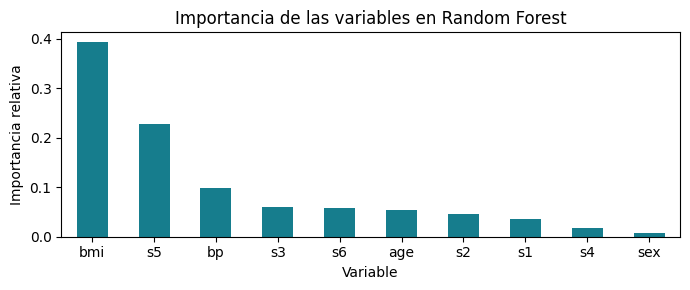

In [11]:
bosque = crear_bosque()
bosque.fit(X_ent, y_ent)
importancias = pd.Series(
    bosque.feature_importances_, index=X.columns, name="Importancia"
).sort_values(ascending=False)
variables_embebido = importancias.head(3).index.tolist()
display(importancias.to_frame().round(3))
print("Seleccionadas por importancia:", variables_embebido)

importancias.plot.bar(color="#167d8d", figsize=(7, 3))
plt.title("Importancia de las variables en Random Forest")
plt.xlabel("Variable")
plt.ylabel("Importancia relativa")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Pregunta 5.** ¿Cuál fue la variable más importante? ¿Las tres elegidas coinciden con las seleccionadas por correlación? ¿El bosque eliminó columnas automáticamente o lo hicimos nosotros?

**Respuesta:**

## 9. Comparación final con los datos de prueba

Ya fijamos los subconjuntos. Ahora entrenaremos nuevamente cada alternativa con **entrenamiento y validación juntos** (80 % de los datos) y la evaluaremos en la **prueba reservada** (20 %).

Compararemos cinco alternativas: todas las variables, filtrado, wrapper hacia adelante, wrapper hacia atrás e importancias del modelo. Son **tres familias de selección**; el wrapper tiene dos recorridos.

Usaremos la misma configuración de Random Forest en todos los casos. No cambiaremos las selecciones después de observar la prueba.

In [12]:
selecciones = {
    "Todas las variables": list(X.columns),
    "Filtrado": variables_filtro,
    "Wrapper: adelante": variables_adelante,
    "Wrapper: atrás": variables_atras,
    "Importancias RF": variables_embebido
}
resultados = []
for metodo, variables in selecciones.items():
    columnas = [v for v in X.columns if v in variables]
    modelo = crear_bosque()
    modelo.fit(X_desarrollo[columnas], y_desarrollo)
    predicciones = modelo.predict(X_prueba[columnas])
    rmse = np.sqrt(mean_squared_error(y_prueba, predicciones))
    resultados.append({
        "Método": metodo,
        "Variables": ", ".join(columnas),
        "Cantidad": len(columnas),
        "RMSE prueba": rmse
    })
comparacion = pd.DataFrame(resultados)
display(comparacion.round(3))

,Método,Variables,Cantidad,RMSE prueba
0,Todas las variables,"age, sex, bmi, bp, s1, s2, s3, s4, s5, s6",10,53.189
1,Filtrado,"bmi, bp, s5",3,52.839
2,Wrapper: adelante,"bmi, s1, s4, s5",4,55.565
3,Wrapper: atrás,"bmi, s2, s4, s5",4,54.254
4,Importancias RF,"bmi, bp, s5",3,52.839


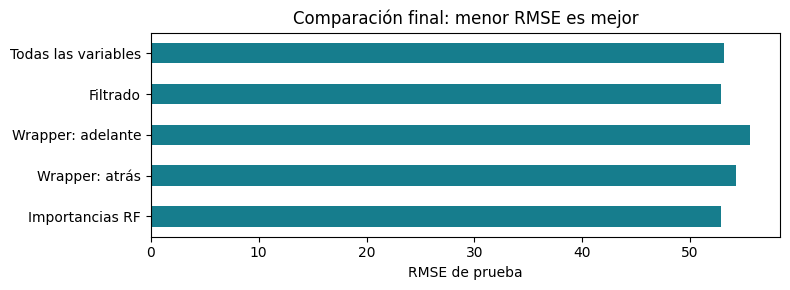

In [13]:
comparacion.plot.barh(
    x="Método", y="RMSE prueba", legend=False,
    color="#167d8d", figsize=(8, 3)
)
plt.title("Comparación final: menor RMSE es mejor")
plt.xlabel("RMSE de prueba")
plt.ylabel("")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 10. Preguntas finales

1. ¿Qué alternativa obtuvo el menor RMSE de prueba? Si hubo empate, indícalo.
2. Compara el RMSE del modelo completo con el de un modelo de tres variables. ¿Cuánto cambió el error al reducir las entradas de diez a tres?
3. ¿Qué método selecciona sin entrenar Random Forest? ¿Cuál necesita entrenar varios modelos para probar subconjuntos?
4. ¿Por qué reservamos los datos de prueba hasta el final?
5. Escribe una conclusión de dos o tres líneas: ¿fue útil seleccionar variables en este ejemplo? Justifica con las variables elegidas y los errores obtenidos.

**Respuestas:**

1.
2.
3.
4.
5.

**Para interpretar:** si varios métodos seleccionan el mismo conjunto, pueden obtener el mismo RMSE con esta configuración y semilla. Es un resultado válido. Seleccionar variables no garantiza mejorar siempre y esta práctica utiliza una sola partición para mantener el procedimiento sencillo.

**Material de apoyo:** conceptos de las diapositivas de clase; código preparado para este laboratorio y datos de [Diabetes de scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html). Documentación: [RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html) y [selección de características](https://scikit-learn.org/stable/modules/feature_selection.html).